In [1]:
using DynamicEnergy.ChilledWater: WaterPort, Boundary_pT, MixingVolume, PressureDrop, Pump_dp
using ModelingToolkitStandardLibrary.Blocks: LimPI, Constant

In [2]:
using ModelingToolkit: equations, observed, mtkcompile, connect, System
using ModelingToolkit: @parameters, @named
using ModelingToolkit: t_nounits as t

settings = (
    inlet_T = 313.15, initial_T = 293.15, volume = 1.0,
    density = 997.0, specific_heat = 4186.0,
    boundary_p = 101325.0, pump_dp = 100000.0,
    nominal_flow = 1.0, nominal_dp = 1000.0,
    tspan = (0.0, 1000.0), reltol = 1e-8, abstol = 1e-8, dtmax = 2.0,
)
# @parameters heat_flux::Float64 = -420000.0
systems = @named begin
    Source = Boundary_pT(p = settings.boundary_p, T = settings.inlet_T)
    Sink = Boundary_pT(p = settings.boundary_p, T = settings.initial_T)
    Pump = Pump_dp(dp = settings.pump_dp)
    Pipe = PressureDrop(nominalFlowRate = settings.nominal_flow,
        nominalPressureDrop = settings.nominal_dp)
    Tank = MixingVolume(volume = settings.volume, T_init = settings.initial_T, use_heat_flux = true)

    # heat_flux = Constant(k = -420000.0)
    flux_controller = LimPI(; k = 5000, T = 1, Ta = 200, u_max = 4200000.0)
end
connections = [
    connect(Source.port, Pump.port1),
    connect(Pump.port2, Pipe.port1),
    connect(Pipe.port2, Tank.port_1),
    connect(Tank.port_2, Sink.port),

    flux_controller.err_input.u ~ -(Tank.T - (35 + 273.15)),
    flux_controller.ctr_output.u ~ Tank.flux_input.u
]
@named raw_model = System(connections, t, [], [];
    systems = systems)
sys = mtkcompile(raw_model)
display(sys)
println("\nEquations:")
foreach(println, equations(sys))
println("\nObserved:",)
foreach(println, observed(sys))

Model raw_model:
Equations (3):
  3 standard: see equations(raw_model)
Unknowns (3): see unknowns(raw_model)
  flux_controller₊addPI₊input2₊u(t): Inner variable in RealInput input2
  Pipe₊port1₊mFlow(t)
  Tank₊T(t)
Parameters (17): see parameters(raw_model)
  flux_controller₊k: Proportional gain
  flux_controller₊T: Integrator time constant
  flux_controller₊Ta: Tracking time constant
  flux_controller₊u_max: Upper saturation limit
  ⋮
Observed (51): see observed(raw_model)


Equations:
Differential(t, 1)(flux_controller₊addPI₊input2₊u(t)) ~ flux_controller₊addTrack₊output₊u(t)*flux_controller₊int₊k
0 ~ -Pipe₊port1₊p(t) + Pipe₊port2₊p(t) + 1000.0Pipe₊port1₊mFlow(t)*abs(Pipe₊port1₊mFlow(t))
Differential(t, 1)(Tank₊T(t)) ~ (-Tank₊flux_input₊u(t) + Pipe₊port1₊mFlow(t)*ifelse(0 < (-Pipe₊port1₊mFlow(t)), Sink₊port₊h_outflow(t), 4186.0(-273.15 + Tank₊T(t))) - Pipe₊port1₊mFlow(t)*ifelse(0 < Pipe₊port1₊mFlow(t), Pipe₊port2₊h_outflow(t), 4186.0(-273.15 + Tank₊T(t)))) / -4.173442e6

Observed:
Sink₊port₊h_outflow(t) ~ 83720.0
Pump₊port1₊p(t) ~ 101325.0
Pipe₊port2₊p(t) ~ 101325.0
Pipe₊port2₊h_outflow(t) ~ 167440.0
flux_controller₊addPI₊input1₊u(t) ~ 308.15 - Tank₊T(t)
Pipe₊port2₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Pump₊port2₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Tank₊port_1₊mFlow(t) ~ Pipe₊port1₊mFlow(t)
Pump₊port1₊mFlow(t) ~ Pipe₊port1₊mFlow(t)
Source₊port₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
Sink₊port₊mFlow(t) ~ Pipe₊port1₊mFlow(t)
Tank₊port_2₊mFlow(t) ~ -Pipe₊port1₊mFlow(t)
flux_

In [3]:
using ModelingToolkit: ODEProblem, solve
using DifferentialEquations
prob = ODEProblem(sys, [], settings.tspan)
display(prob)
display(prob.f.mass_matrix)
# sol = solve(
#     prob,
#     Rodas5P();
#     abstol = 1e-9,
#     reltol = 1e-8
# )
sol = solve(prob)

ODEProblem with uType Vector{Float64} and tType Float64. In-place: true
Initialization status: FULLY_DETERMINED
Non-trivial mass matrix: true
timespan: (0.0, 1000.0)
u0: 3-element Vector{Float64}:
   0.0
   1.0
 293.15

3×3 LinearAlgebra.Diagonal{Float64, Vector{Float64}}:
 1.0   ⋅    ⋅ 
  ⋅   0.0   ⋅ 
  ⋅    ⋅   1.0

retcode: Success
Interpolation: 3rd order Hermite
t: 39-element Vector{Float64}:
    0.0
    1.0e-6
    4.224296909190323e-5
    0.00045467266001093554
    0.004578969569201258
    0.045821938661104476
    0.4582516295801366
    3.0248067908118577
    9.746815634129925
   20.25971850772581
    ⋮
  635.4610251942154
  672.5799908836387
  721.3380656780137
  759.478999443284
  810.1041655880543
  851.1406269259274
  906.1125963848903
  951.7176724659362
 1000.0
u: 39-element Vector{Vector{Float64}}:
 [0.0, 10.0, 293.15]
 [1.499999989071358e-5, 10.0, 293.15000021857253]
 [0.0006336443413604194, 10.0, 293.1500092331687]
 [0.006820067307468908, 10.0, 293.15009938058176]
 [0.0686822518881824, 10.0, 293.15100099986955]
 [0.6870993682183911, 10.0, 293.16003170224843]
 [6.850576859399666, 10.0, 293.2517834256726]
 [44.30216972116248, 10.0, 293.880066335691]
 [133.5985930160554, 10.0, 295.945485667207]
 [240.91715540005774, 10.0, 300.0819767618047]
 ⋮
 [-39.42258758681908, 10.0, 308.587380812615

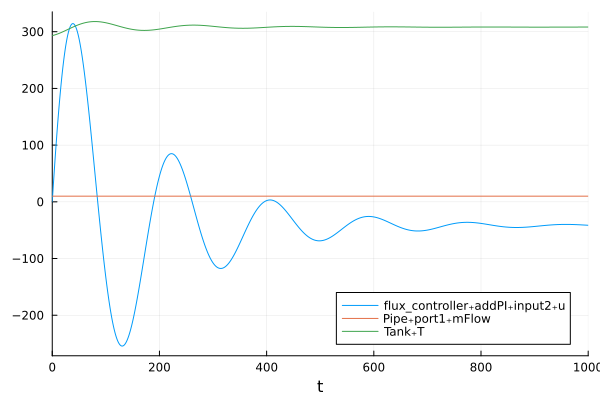

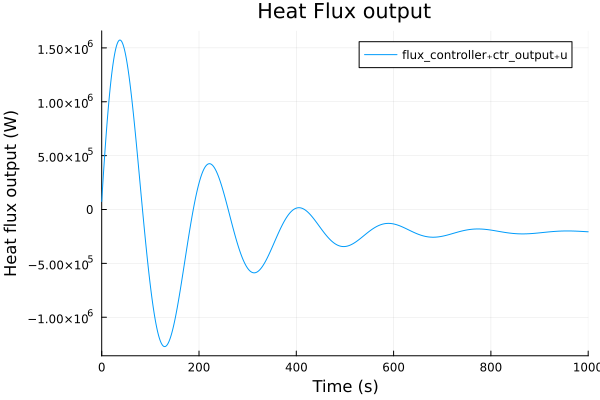

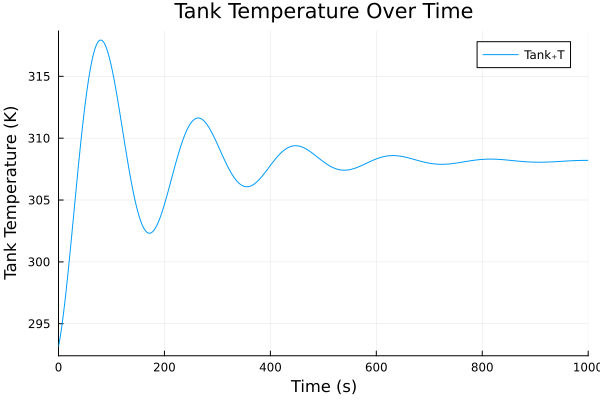

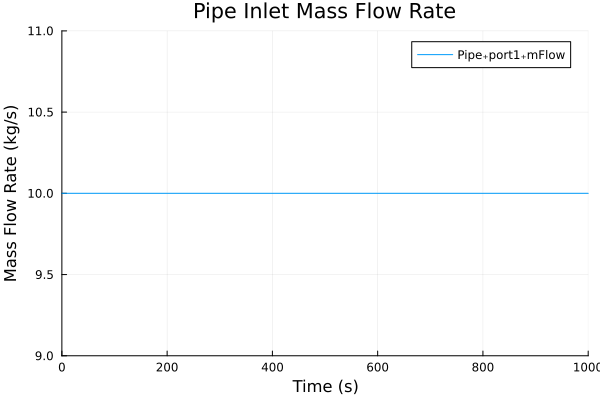

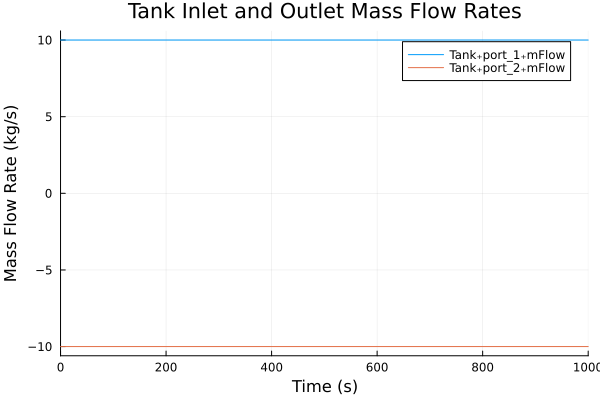

In [4]:
using Plots: plot
display(plot(sol))
display(plot(sol; idxs = [flux_controller.ctr_output.u], xlabel = "Time (s)", ylabel = "Heat flux output (W)", title = "Heat Flux output"))
display(plot(sol; idxs = [Tank.T], xlabel = "Time (s)", ylabel = "Tank Temperature (K)", title = "Tank Temperature Over Time"))
display(plot(sol; idxs = [Pipe.port1.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Pipe Inlet Mass Flow Rate", ylims = (9.0, 11.0)))
display(plot(sol; idxs = [Tank.port_1.mFlow, Tank.port_2.mFlow], xlabel = "Time (s)", ylabel = "Mass Flow Rate (kg/s)", title = "Tank Inlet and Outlet Mass Flow Rates"))

In [5]:
ts = collect(0.0:10.0:600.0)

vars = [Tank.T, Pipe.port1.mFlow, Tank.port_1.mFlow, Tank.port_2.mFlow]

data = hcat([sol(t; idxs = vars) for t in ts]...)
display(data)
data = permutedims(data)
display(data)
data_with_time = hcat(ts, data)
display(data_with_time)

column_name = ["Time (s)", "Tank Temperature (K)", "Pipe Inlet Mass Flow Rate (kg/s)", "Tank Inlet Mass Flow Rate (kg/s)", "Tank Outlet Mass Flow Rate (kg/s)"]

using DataFrames
df = DataFrame(data_with_time, Symbol.(column_name))
display(df)

4×61 Matrix{Float64}:
 293.15  296.034  299.971  304.407  …  307.745  307.943  308.143  308.322
  10.0    10.0     10.0     10.0        10.0     10.0     10.0     10.0
  10.0    10.0     10.0     10.0        10.0     10.0     10.0     10.0
 -10.0   -10.0    -10.0    -10.0       -10.0    -10.0    -10.0    -10.0

61×4 Matrix{Float64}:
 293.15   10.0  10.0  -10.0
 296.034  10.0  10.0  -10.0
 299.971  10.0  10.0  -10.0
 304.407  10.0  10.0  -10.0
 308.792  10.0  10.0  -10.0
 312.64   10.0  10.0  -10.0
 315.575  10.0  10.0  -10.0
 317.365  10.0  10.0  -10.0
 317.931  10.0  10.0  -10.0
 317.34   10.0  10.0  -10.0
   ⋮                  
 307.587  10.0  10.0  -10.0
 307.453  10.0  10.0  -10.0
 307.41   10.0  10.0  -10.0
 307.456  10.0  10.0  -10.0
 307.574  10.0  10.0  -10.0
 307.745  10.0  10.0  -10.0
 307.943  10.0  10.0  -10.0
 308.143  10.0  10.0  -10.0
 308.322  10.0  10.0  -10.0

61×5 Matrix{Float64}:
   0.0  293.15   10.0  10.0  -10.0
  10.0  296.034  10.0  10.0  -10.0
  20.0  299.971  10.0  10.0  -10.0
  30.0  304.407  10.0  10.0  -10.0
  40.0  308.792  10.0  10.0  -10.0
  50.0  312.64   10.0  10.0  -10.0
  60.0  315.575  10.0  10.0  -10.0
  70.0  317.365  10.0  10.0  -10.0
  80.0  317.931  10.0  10.0  -10.0
  90.0  317.34   10.0  10.0  -10.0
   ⋮                         
 520.0  307.587  10.0  10.0  -10.0
 530.0  307.453  10.0  10.0  -10.0
 540.0  307.41   10.0  10.0  -10.0
 550.0  307.456  10.0  10.0  -10.0
 560.0  307.574  10.0  10.0  -10.0
 570.0  307.745  10.0  10.0  -10.0
 580.0  307.943  10.0  10.0  -10.0
 590.0  308.143  10.0  10.0  -10.0
 600.0  308.322  10.0  10.0  -10.0

Row,Time (s),Tank Temperature (K),Pipe Inlet Mass Flow Rate (kg/s),Tank Inlet Mass Flow Rate (kg/s),Tank Outlet Mass Flow Rate (kg/s)
,Float64,Float64,Float64,Float64,Float64
1,0.0,293.15,10.0,10.0,-10.0
2,10.0,296.034,10.0,10.0,-10.0
3,20.0,299.971,10.0,10.0,-10.0
4,30.0,304.407,10.0,10.0,-10.0
5,40.0,308.792,10.0,10.0,-10.0
6,50.0,312.64,10.0,10.0,-10.0
7,60.0,315.575,10.0,10.0,-10.0
8,70.0,317.365,10.0,10.0,-10.0
9,80.0,317.931,10.0,10.0,-10.0
